<a href="https://colab.research.google.com/github/weagan/Derivative-Free-Optimization-DFO-/blob/main/astra6_weight_guessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Astra-6 Style Weight Guessing and Reconstruction Demo

This notebook demonstrates a zero-order optimization / evolutionary strategy to
reverse-engineer or mimic a target model fingerprint. Instead of using standard
backpropagation, it directly "guesses" and optimizes a weight set to match a specific
static output fingerprint.

Built to run seamlessly on both **Google Colab** and **Kaggle**, including automated
cross-platform secret handling.

In [1]:
import os
import sys
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# ==========================================
# 1. CROSS-PLATFORM SECRET HANDLING
# ==========================================
def get_platform_secret(secret_name, default_value="MOCK_API_KEY"):
    """
    Safely fetches secrets across Google Colab and Kaggle environments.
    If run locally, falls back to environment variables or a default value.
    """
    # Detect Google Colab
    if 'google.colab' in sys.modules:
        try:
            from google.colab import secrets
            print(f"[Colab] Attempting to fetch secret: {secret_name}")
            return secrets.get(secret_name)
        except Exception as e:
            print(f"[Colab] Could not retrieve secret via Google Secrets: {e}")

    # Detect Kaggle
    elif os.environ.get('KAGGLE_KERNEL_RUN_TYPE') is not None:
        try:
            from kaggle_secrets import UserSecretsClient
            print(f"[Kaggle] Attempting to fetch secret: {secret_name}")
            user_secrets = UserSecretsClient()
            return user_secrets.get_secret(secret_name)
        except Exception as e:
            print(f"[Kaggle] Could not retrieve secret via Kaggle Secrets: {e}")

    # Local or Fallback
    print(f"[Fallback] Fetching secret '{secret_name}' from environment or default.")
    return os.environ.get(secret_name, default_value)

# Example invocation fetching a placeholder token/API key
ASTRA_API_KEY = get_platform_secret("ASTRA_AUTH_KEY", "default_astra_6_key_12345")
print(f"Secret successfully configured (Length: {len(ASTRA_API_KEY)})")

[Colab] Could not retrieve secret via Google Secrets: cannot import name 'secrets' from 'google.colab' (/usr/local/lib/python3.13/dist-packages/google/colab/__init__.py)
[Fallback] Fetching secret 'ASTRA_AUTH_KEY' from environment or default.
Secret successfully configured (Length: 25)


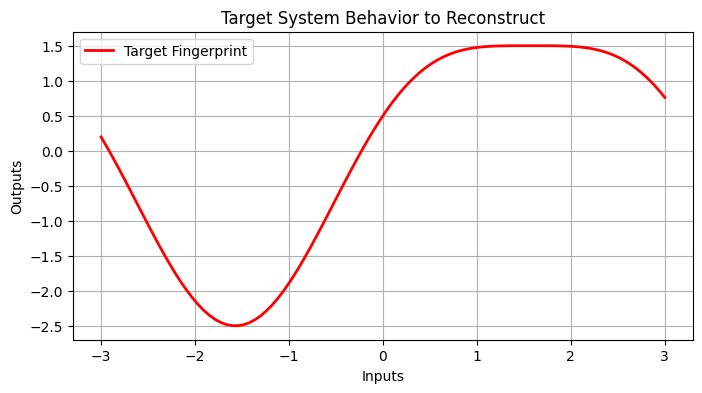

In [2]:
# ==========================================
# 2. DEFINE THE TARGET BLACK-BOX FINGERPRINT
# ==========================================
# We define a static function representing our target fingerprint or black-box system.
# The goal of our weight guessing model is to replicate this behavior exactly without gradients.

np.random.seed(42)
torch.manual_seed(42)

# Generate a static dataset representing the target system behavior
X_target = torch.linspace(-3.0, 3.0, 100).view(-1, 1)
# Target output: A complex nonlinear static fingerprint
Y_target = torch.sin(X_target) * 2.0 + torch.cos(X_target * 2.0) * 0.5

plt.figure(figsize=(8, 4))
plt.plot(X_target.numpy(), Y_target.numpy(), label="Target Fingerprint", color='red', lw=2)
plt.title("Target System Behavior to Reconstruct")
plt.xlabel("Inputs")
plt.ylabel("Outputs")
plt.legend()
plt.grid(True)
plt.show()

In [3]:
# ==========================================
# 3. DEFINE THE RECONSTRUCTION MODEL
# ==========================================
class SmallReconstructionNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 16),
            nn.Tanh(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.net(x)

    def get_weights_flat(self):
        """Extract all model weights and biases into a single 1D numpy array."""
        params = [p.data.cpu().numpy().flatten() for p in self.parameters()]
        return np.concatenate(params)

    def set_weights_flat(self, flat_weights):
        """Inject a single 1D numpy array back into the PyTorch network parameters."""
        current_idx = 0
        for p in self.parameters():
            numel = p.numel()
            arr = flat_weights[current_idx:current_idx + numel].reshape(p.shape)
            p.data = torch.from_numpy(arr).float()
            current_idx += numel

# Instantiate base model to find parameter dimensions
base_model = SmallReconstructionNet()
initial_weights = base_model.get_weights_flat()
num_dimensions = len(initial_weights)
print(f"Total parameter profile dimensions to guess: {num_dimensions}")

Total parameter profile dimensions to guess: 49


In [4]:
# ==========================================
# 4. ZERO-ORDER WEIGHT GUESSING LOOP (EVOLUTIONARY STRATEGY)
# ==========================================
def evaluate_weight_profile(model, weights, X, Y):
    """Sets weights into model and evaluates MSE against the target fingerprint."""
    model.set_weights_flat(weights)
    with torch.no_grad():
        predictions = model(X)
        loss = nn.functional.mse_loss(predictions, Y).item()
    return loss

def run_weight_guessing_es(model, X, Y, generations=300, population_size=40, sigma=0.15):
    """
    Implements a simplified zero-order Evolution Strategy to optimize weights
    directly toward matching a target static output fingerprint.
    """
    best_weights = model.get_weights_flat()
    best_loss = evaluate_weight_profile(model, best_weights, X, Y)

    loss_history = [best_loss]
    print(f"Generation 0 | Initial Guess Loss: {best_loss:.6f}")

    for gen in range(1, generations + 1):
        # Sample perturbations (mutations) around the current best candidate
        noise = np.random.randn(population_size, num_dimensions)
        candidates = best_weights + sigma * noise

        losses = []
        for i in range(population_size):
            loss = evaluate_weight_profile(model, candidates[i], X, Y)
            losses.append(loss)

        # Locate the best performer in this generation
        min_idx = np.argmin(losses)
        generation_best_loss = losses[min_idx]

        # If an improvement is found, update our central weight profile
        if generation_best_loss < best_loss:
            best_loss = generation_best_loss
            best_weights = candidates[min_idx]

        loss_history.append(best_loss)

        if gen % 50 == 0 or gen == 1:
            print(f"Generation {gen} | Lowest Reconstruction Loss: {best_loss:.6f}")

    return best_weights, loss_history

# Run the evolutionary guessing engine
optimized_weights, history = run_weight_guessing_es(base_model, X_target, Y_target, generations=400)

Generation 0 | Initial Guess Loss: 0.934473
Generation 1 | Lowest Reconstruction Loss: 0.602443
Generation 50 | Lowest Reconstruction Loss: 0.052300
Generation 100 | Lowest Reconstruction Loss: 0.029944
Generation 150 | Lowest Reconstruction Loss: 0.017015
Generation 200 | Lowest Reconstruction Loss: 0.010842
Generation 250 | Lowest Reconstruction Loss: 0.010842
Generation 300 | Lowest Reconstruction Loss: 0.010842
Generation 350 | Lowest Reconstruction Loss: 0.010842
Generation 400 | Lowest Reconstruction Loss: 0.010842


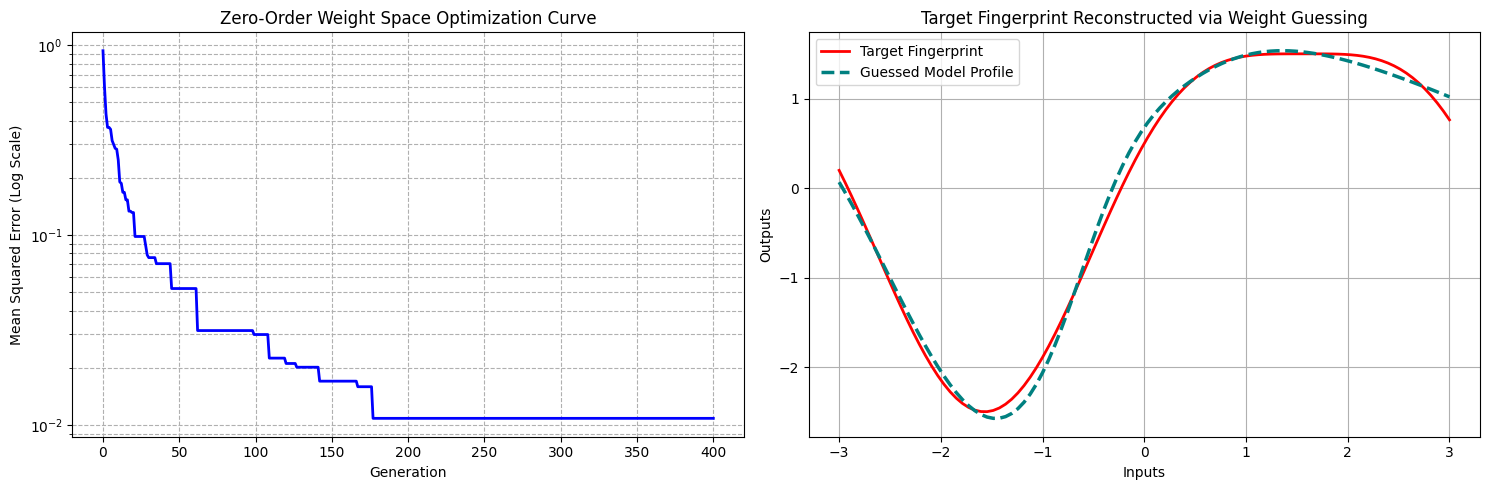

In [6]:
# ==========================================
# 5. VISUALIZE RECONSTRUCTION SUCCESS
# ==========================================
# Load the ultimate best guessed weights back into the network
base_model.set_weights_flat(optimized_weights)
with torch.no_grad():
    guessed_predictions = base_model(X_target).numpy()

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Optimization loss progression over generations
ax[0].plot(history, color='blue', lw=2)
ax[0].set_yscale('log')
ax[0].set_title("Zero-Order Weight Space Optimization Curve")
ax[0].set_xlabel("Generation")
ax[0].set_ylabel("Mean Squared Error (Log Scale)")
ax[0].grid(True, which="both", ls="--")

# Plot 2: Reconstructed model vs. Target Fingerprint
ax[1].plot(X_target.numpy(), Y_target.numpy(), label="Target Fingerprint", color='red', lw=2)
ax[1].plot(X_target.numpy(), guessed_predictions, label="Guessed Model Profile", color='teal', linestyle='--', lw=2.5)
ax[1].set_title("Target Fingerprint Reconstructed via Weight Guessing")
ax[1].set_xlabel("Inputs")
ax[1].set_ylabel("Outputs")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()